# EA-TTM — Reporting and Defense Evidence Package

**Project:** Extreme-Aware Tiny Time Mixers (EA-TTM) for Retail Demand Forecasting under Regime Shifts  
**Phase:** 11 — Reporting, visualization, limitations, and defense evidence  
**Scope:** Convert the locked experimental artifacts into reproducible tables, figures, claims, caveats, and defense-ready evidence.

No model is trained, modified, reselected, or reevaluated in this notebook.

## Governance constraint

Phase 10 sealed the final evaluation:

$$
\text{Post-test tuning} = \text{False}.
$$

Phase 11 may only read locked artifacts, summarize results, compute descriptive comparisons from saved metrics, create reporting figures/tables, and document limitations.

## Reporting principle

The results are reported in three layers:

1. **Base transfer:** zero-shot and head-probed TTM versus seasonal naive.
2. **Primary EA-TTM:** the locked gated model versus frozen HP-TTM.
3. **Ablation evidence:** retail-only and ungated cross-feed variants.

This separation prevents an ablation result from being confused with the pre-registered primary model.

In [1]:
from __future__ import annotations

import json
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Project preflight

In [2]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/EA_TTM_RETAIL")
METADATA_DIR = PROJECT_ROOT / "metadata"
RESULTS_TABLE_DIR = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURE_DIR = PROJECT_ROOT / "results" / "figures"

RESULTS_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

required_artifacts = {
    "phase03_summary": METADATA_DIR / "03_RUN_SUMMARY.json",
    "phase04_summary": METADATA_DIR / "04_RUN_SUMMARY.json",
    "phase08_summary": METADATA_DIR / "08_RUN_SUMMARY.json",
    "phase09_summary": METADATA_DIR / "09_RUN_SUMMARY.json",
    "phase10_summary": METADATA_DIR / "10_RUN_SUMMARY.json",
    "development_lock": METADATA_DIR / "09_MODEL_DEVELOPMENT_LOCK.json",
    "final_evaluation_lock": METADATA_DIR / "10_FINAL_EVALUATION_LOCK.json",
    "final_metrics": RESULTS_TABLE_DIR / "10_FINAL_TEST_METRICS.csv",
    "regime_metrics": RESULTS_TABLE_DIR / "10_FINAL_TEST_REGIME_METRICS.csv",
    "final_mechanism": RESULTS_TABLE_DIR / "10_FINAL_TEST_MECHANISM.csv",
    "bootstrap_evidence": RESULTS_TABLE_DIR / "10_FINAL_TEST_BOOTSTRAP.csv",
    "phase08_history": RESULTS_TABLE_DIR / "08_EA_TTM_TRAINING_HISTORY.csv",
    "phase09_ablation": RESULTS_TABLE_DIR / "09_VALIDATION_ABLATION_COMPARISON.csv",
}

missing = [
    str(path)
    for path in required_artifacts.values()
    if not path.exists()
]

assert not missing, (
    "Phase 11 prerequisites are incomplete: "
    + "; ".join(missing)
)

Mounted at /content/drive


## Load and verify locked experiment state

In [3]:
def load_json(path: Path) -> dict[str, Any]:
    return json.loads(
        path.read_text(
            encoding="utf-8"
        )
    )

phase03 = load_json(METADATA_DIR / "03_RUN_SUMMARY.json")
phase04 = load_json(METADATA_DIR / "04_RUN_SUMMARY.json")
phase08 = load_json(METADATA_DIR / "08_RUN_SUMMARY.json")
phase09 = load_json(METADATA_DIR / "09_RUN_SUMMARY.json")
phase10 = load_json(METADATA_DIR / "10_RUN_SUMMARY.json")

development_lock = load_json(
    METADATA_DIR / "09_MODEL_DEVELOPMENT_LOCK.json"
)

final_evaluation_lock = load_json(
    METADATA_DIR / "10_FINAL_EVALUATION_LOCK.json"
)

assert development_lock["post_lock_tuning_permitted"] is False
assert final_evaluation_lock["post_test_tuning_permitted"] is False
assert final_evaluation_lock["test_results_may_change_model_selection"] is False

PRIMARY_MODEL = development_lock["primary_model"]
PRIMARY_EPOCH = int(
    development_lock["primary_epoch"]
)

assert PRIMARY_MODEL == "Phase 08 best-balanced EA-TTM"
assert PRIMARY_EPOCH == 15

print("Primary model:", PRIMARY_MODEL)
print("Primary epoch:", PRIMARY_EPOCH)
print("Post-test tuning permitted:", False)

Primary model: Phase 08 best-balanced EA-TTM
Primary epoch: 15
Post-test tuning permitted: False


## Master final-test results

In [4]:
final_metrics = pd.read_csv(
    RESULTS_TABLE_DIR / "10_FINAL_TEST_METRICS.csv"
)

regime_metrics = pd.read_csv(
    RESULTS_TABLE_DIR / "10_FINAL_TEST_REGIME_METRICS.csv"
)

master_results = final_metrics.merge(
    regime_metrics,
    on="model",
    how="inner",
    validate="one_to_one",
)

MASTER_RESULTS_PATH = (
    RESULTS_TABLE_DIR
    / "11_MASTER_RESULTS_TABLE.csv"
)

master_results.to_csv(
    MASTER_RESULTS_PATH,
    index=False,
)

master_results

,model,mse,rmse,mae,wape,normal_mse,extreme_mse,positive_extreme_mse,negative_extreme_mse
0,Weekly Seasonal Naive,7.165766,2.676895,1.243972,0.862181,4.466177,50.009881,49.857236,52.231786
1,Zero-shot TTM,4.637857,2.153569,1.041414,0.721791,2.107093,44.802609,44.702207,46.264069
2,Frozen HP-TTM,4.563047,2.136129,1.028902,0.713119,2.067278,44.172408,44.064259,45.746637
3,Retail-only gated adapter,4.532796,2.129037,1.038483,0.719759,2.089553,43.308546,43.125029,45.979846
4,Ungated cross-feed adapter,4.513243,2.124439,1.041909,0.722134,2.131107,42.319173,41.821251,49.566982
5,Primary EA-TTM,4.528610,2.128053,1.037919,0.719369,2.082416,43.351182,43.126123,46.627155


## Derived comparisons

A positive percentage denotes lower error for the candidate relative to its baseline.

In [5]:
def improvement_percent(
    baseline: float,
    candidate: float,
) -> float:
    return float(
        100.0
        * (baseline - candidate)
        / baseline
    )

results_by_model = (
    master_results
    .set_index("model")
    .to_dict(orient="index")
)

comparison_pairs = [
    (
        "Zero-shot TTM",
        "Weekly Seasonal Naive",
        "Zero-shot vs Seasonal Naive",
    ),
    (
        "Frozen HP-TTM",
        "Zero-shot TTM",
        "HP-TTM vs Zero-shot TTM",
    ),
    (
        "Primary EA-TTM",
        "Frozen HP-TTM",
        "Primary EA-TTM vs HP-TTM",
    ),
    (
        "Ungated cross-feed adapter",
        "Frozen HP-TTM",
        "Ungated cross-feed vs HP-TTM",
    ),
    (
        "Primary EA-TTM",
        "Retail-only gated adapter",
        "Primary EA-TTM vs Retail-only gated",
    ),
]

comparison_metrics = [
    "mse",
    "rmse",
    "mae",
    "wape",
    "normal_mse",
    "extreme_mse",
    "positive_extreme_mse",
    "negative_extreme_mse",
]

comparison_records = []

for candidate, baseline, label in comparison_pairs:
    record = {
        "comparison": label,
        "candidate": candidate,
        "baseline": baseline,
    }

    for metric in comparison_metrics:
        record[
            f"{metric}_improvement_percent"
        ] = improvement_percent(
            results_by_model[baseline][metric],
            results_by_model[candidate][metric],
        )

    comparison_records.append(record)

comparison_table = pd.DataFrame(
    comparison_records
)

COMPARISON_TABLE_PATH = (
    RESULTS_TABLE_DIR
    / "11_DERIVED_COMPARISONS.csv"
)

comparison_table.to_csv(
    COMPARISON_TABLE_PATH,
    index=False,
)

comparison_table

,comparison,candidate,baseline,mse_improvement_percent,rmse_improvement_percent,mae_improvement_percent,wape_improvement_percent,normal_mse_improvement_percent,extreme_mse_improvement_percent,positive_extreme_mse_improvement_percent,negative_extreme_mse_improvement_percent
0,Zero-shot vs Seasonal Naive,Zero-shot TTM,Weekly Seasonal Naive,35.277581,19.549755,16.283162,16.283162,52.821096,10.412485,10.339580,11.425451
1,HP-TTM vs Zero-shot TTM,Frozen HP-TTM,Zero-shot TTM,1.613038,0.809798,1.201430,1.201430,1.889591,1.406617,1.427107,1.118430
2,Primary EA-TTM vs HP-TTM,Primary EA-TTM,Frozen HP-TTM,0.754695,0.378062,-0.876354,-0.876354,-0.732276,1.859138,2.129017,-1.924771
3,Ungated cross-feed vs HP-TTM,Ungated cross-feed adapter,Frozen HP-TTM,1.091460,0.547227,-1.264118,-1.264118,-3.087615,4.195458,5.090311,-8.351093
4,Primary EA-TTM vs Retail-only gated,Primary EA-TTM,Retail-only gated adapter,0.092363,0.046192,0.054258,0.054258,0.341549,-0.098445,-0.002538,-1.407810


## Figure 1 — Locked final-test MSE

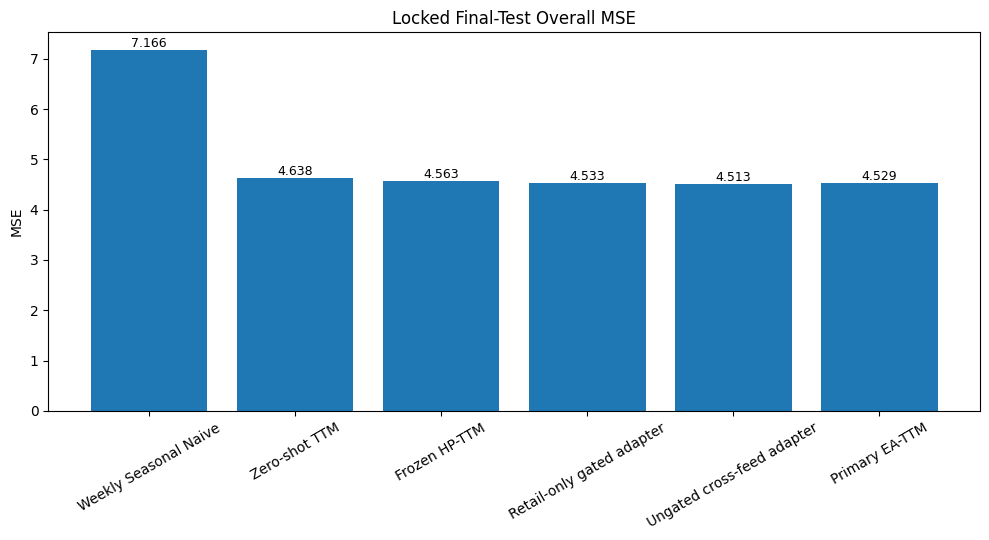

In [6]:
FIG01_PATH = (
    RESULTS_FIGURE_DIR
    / "11_FIG01_FINAL_TEST_MSE.png"
)

figure_order = [
    "Weekly Seasonal Naive",
    "Zero-shot TTM",
    "Frozen HP-TTM",
    "Retail-only gated adapter",
    "Ungated cross-feed adapter",
    "Primary EA-TTM",
]

plot_frame = (
    master_results
    .set_index("model")
    .loc[figure_order]
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

bars = ax.bar(
    plot_frame["model"],
    plot_frame["mse"],
)

ax.set_ylabel("MSE")
ax.set_title(
    "Locked Final-Test Overall MSE"
)
ax.tick_params(
    axis="x",
    rotation=30,
)

for bar, value in zip(
    bars,
    plot_frame["mse"],
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
fig.savefig(
    FIG01_PATH,
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## Figure 2 — Normal versus extreme MSE

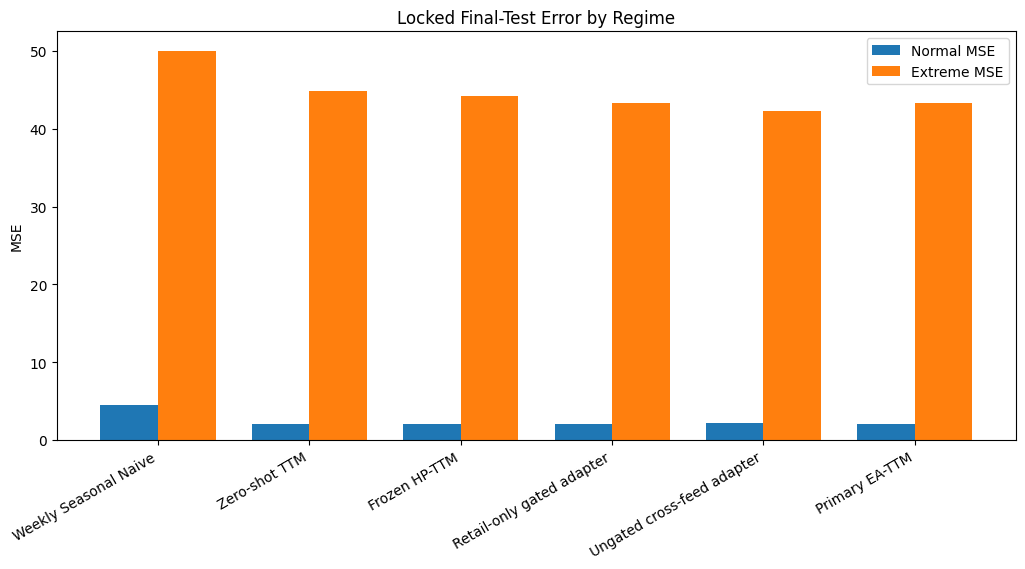

In [7]:
FIG02_PATH = (
    RESULTS_FIGURE_DIR
    / "11_FIG02_NORMAL_EXTREME_MSE.png"
)

regime_plot = (
    master_results
    .set_index("model")
    .loc[figure_order]
)

x = np.arange(
    len(regime_plot)
)
width = 0.38

fig, ax = plt.subplots(
    figsize=(10.5, 5.8)
)

ax.bar(
    x - width / 2,
    regime_plot["normal_mse"],
    width,
    label="Normal MSE",
)

ax.bar(
    x + width / 2,
    regime_plot["extreme_mse"],
    width,
    label="Extreme MSE",
)

ax.set_xticks(x)
ax.set_xticklabels(
    figure_order,
    rotation=30,
    ha="right",
)
ax.set_ylabel("MSE")
ax.set_title(
    "Locked Final-Test Error by Regime"
)
ax.legend()

fig.tight_layout()
fig.savefig(
    FIG02_PATH,
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## Figure 3 — Primary EA-TTM change versus HP-TTM

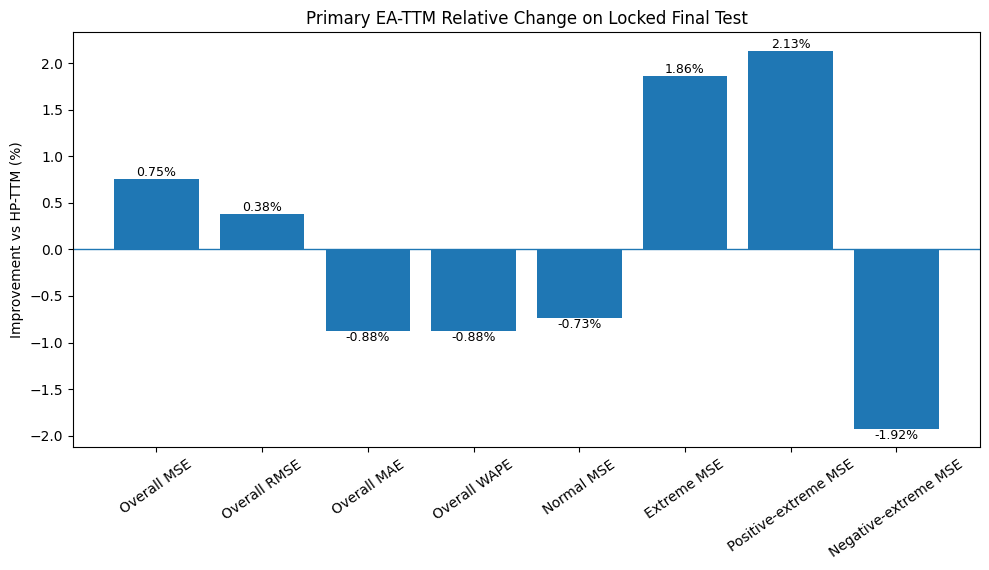

In [8]:
FIG03_PATH = (
    RESULTS_FIGURE_DIR
    / "11_FIG03_PRIMARY_VS_HP_PERCENT_CHANGE.png"
)

primary_vs_hp = (
    phase10[
        "primary_ea_vs_hp_percent"
    ]
)

metric_labels = [
    "Overall MSE",
    "Overall RMSE",
    "Overall MAE",
    "Overall WAPE",
    "Normal MSE",
    "Extreme MSE",
    "Positive-extreme MSE",
    "Negative-extreme MSE",
]

metric_keys = [
    "overall_mse_improvement_percent",
    "overall_rmse_improvement_percent",
    "overall_mae_improvement_percent",
    "overall_wape_improvement_percent",
    "normal_mse_improvement_percent",
    "extreme_mse_improvement_percent",
    "positive_extreme_mse_improvement_percent",
    "negative_extreme_mse_improvement_percent",
]

values = [
    primary_vs_hp[key]
    for key in metric_keys
]

fig, ax = plt.subplots(
    figsize=(10, 5.8)
)

bars = ax.bar(
    metric_labels,
    values,
)

ax.axhline(
    0.0,
    linewidth=1.0,
)

ax.set_ylabel(
    "Improvement vs HP-TTM (%)"
)
ax.set_title(
    "Primary EA-TTM Relative Change on Locked Final Test"
)
ax.tick_params(
    axis="x",
    rotation=35,
)

for bar, value in zip(
    bars,
    values,
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value,
        f"{value:.2f}%",
        ha="center",
        va=(
            "bottom"
            if value >= 0
            else "top"
        ),
        fontsize=9,
    )

fig.tight_layout()
fig.savefig(
    FIG03_PATH,
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## Figure 4 — Gate mechanism

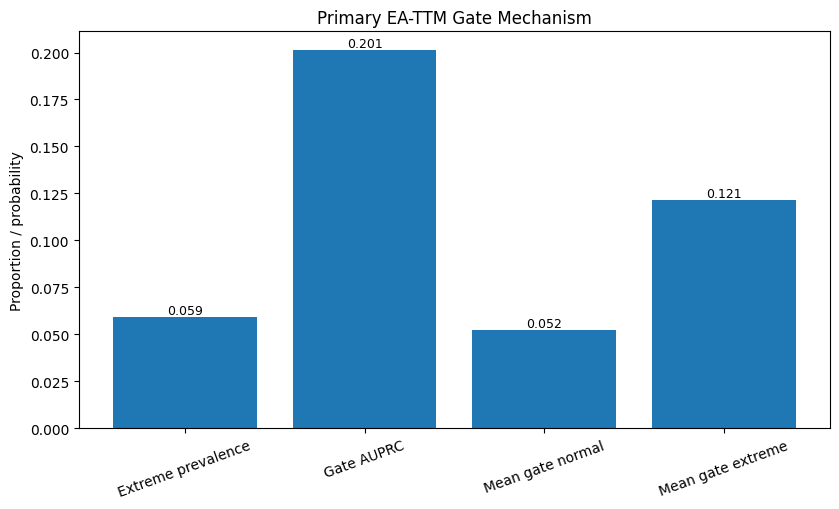

In [9]:
FIG04_PATH = (
    RESULTS_FIGURE_DIR
    / "11_FIG04_GATE_MECHANISM.png"
)

mechanism = phase10[
    "primary_mechanism"
]

gate_categories = [
    "Extreme prevalence",
    "Gate AUPRC",
    "Mean gate normal",
    "Mean gate extreme",
]

gate_values = [
    mechanism["test_extreme_rate"],
    mechanism["gate_auprc"],
    mechanism["mean_gate_normal"],
    mechanism["mean_gate_extreme"],
]

fig, ax = plt.subplots(
    figsize=(8.5, 5.2)
)

bars = ax.bar(
    gate_categories,
    gate_values,
)

ax.set_ylabel(
    "Proportion / probability"
)
ax.set_title(
    "Primary EA-TTM Gate Mechanism"
)
ax.tick_params(
    axis="x",
    rotation=20,
)

for bar, value in zip(
    bars,
    gate_values,
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
fig.savefig(
    FIG04_PATH,
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## Figure 5 — Paired bootstrap interval

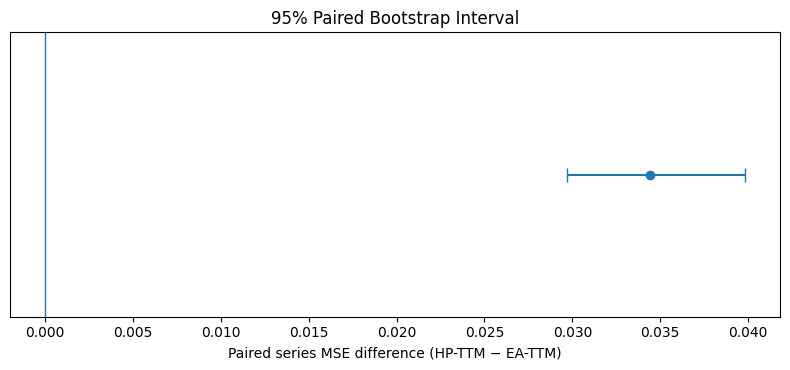

In [10]:
FIG05_PATH = (
    RESULTS_FIGURE_DIR
    / "11_FIG05_BOOTSTRAP_EA_VS_HP.png"
)

bootstrap = phase10[
    "paired_bootstrap"
]

observed = float(
    bootstrap[
        "observed_mse_difference_hp_minus_ea"
    ]
)

ci_lower = float(
    bootstrap["ci_95_lower"]
)

ci_upper = float(
    bootstrap["ci_95_upper"]
)

fig, ax = plt.subplots(
    figsize=(8, 3.8)
)

ax.errorbar(
    [observed],
    [0],
    xerr=[
        [observed - ci_lower],
        [ci_upper - observed],
    ],
    fmt="o",
    capsize=5,
)

ax.axvline(
    0.0,
    linewidth=1.0,
)

ax.set_yticks([])
ax.set_xlabel(
    "Paired series MSE difference (HP-TTM − EA-TTM)"
)
ax.set_title(
    "95% Paired Bootstrap Interval"
)

fig.tight_layout()
fig.savefig(
    FIG05_PATH,
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## Figure 6 — Validation-to-test consistency

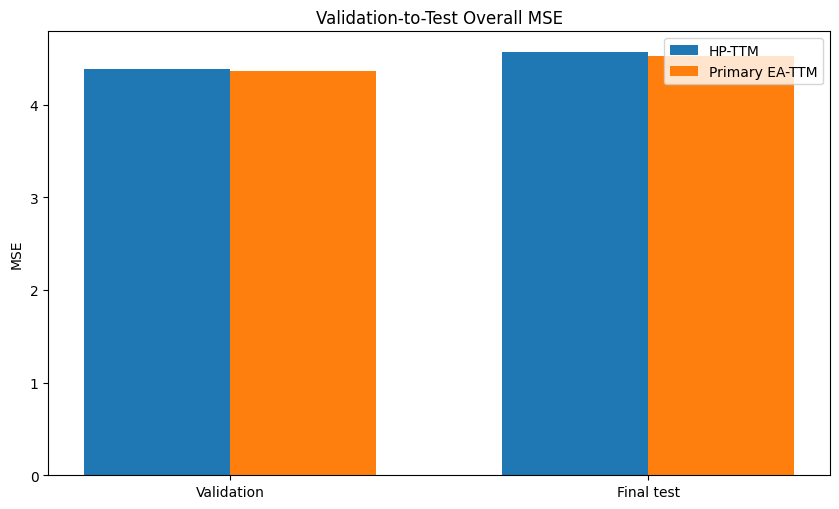

In [11]:
FIG06_PATH = (
    RESULTS_FIGURE_DIR
    / "11_FIG06_VALIDATION_TEST_CONSISTENCY.png"
)

consistency_frame = pd.DataFrame(
    [
        {
            "split": "Validation",
            "HP-TTM": phase08[
                "hp_ttm_validation_metrics"
            ]["mse"],
            "Primary EA-TTM": phase08[
                "ea_ttm_validation_metrics"
            ]["mse"],
        },
        {
            "split": "Final test",
            "HP-TTM": results_by_model[
                "Frozen HP-TTM"
            ]["mse"],
            "Primary EA-TTM": results_by_model[
                "Primary EA-TTM"
            ]["mse"],
        },
    ]
)

x = np.arange(2)
width = 0.35

fig, ax = plt.subplots(
    figsize=(8.5, 5.2)
)

ax.bar(
    x - width / 2,
    consistency_frame[
        "HP-TTM"
    ],
    width,
    label="HP-TTM",
)

ax.bar(
    x + width / 2,
    consistency_frame[
        "Primary EA-TTM"
    ],
    width,
    label="Primary EA-TTM",
)

ax.set_xticks(x)
ax.set_xticklabels(
    consistency_frame["split"]
)
ax.set_ylabel("MSE")
ax.set_title(
    "Validation-to-Test Overall MSE"
)
ax.legend()

fig.tight_layout()
fig.savefig(
    FIG06_PATH,
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## Model complexity

In [12]:
complexity_table = pd.DataFrame(
    [
        {
            "model": "Frozen HP-TTM",
            "total_parameters": int(
                phase04["total_parameters"]
            ),
            "trainable_parameters_in_final_stage": 0,
        },
        {
            "model": "Retail-only gated adapter",
            "total_parameters": np.nan,
            "trainable_parameters_in_final_stage": int(
                phase09[
                    "retail_only_validation"
                ]["parameter_count"]
            ),
        },
        {
            "model": "Ungated cross-feed adapter",
            "total_parameters": np.nan,
            "trainable_parameters_in_final_stage": int(
                phase09[
                    "ungated_crossfeed_validation"
                ]["parameter_count"]
            ),
        },
        {
            "model": "Primary EA-TTM adapter",
            "total_parameters": np.nan,
            "trainable_parameters_in_final_stage": int(
                phase08[
                    "adapter_trainable_parameters"
                ]
            ),
        },
    ]
)

COMPLEXITY_TABLE_PATH = (
    RESULTS_TABLE_DIR
    / "11_MODEL_COMPLEXITY.csv"
)

complexity_table.to_csv(
    COMPLEXITY_TABLE_PATH,
    index=False,
)

complexity_table

,model,total_parameters,trainable_parameters_in_final_stage
0,Frozen HP-TTM,799756.0,0
1,Retail-only gated adapter,NaN,418
2,Ungated cross-feed adapter,NaN,2449
3,Primary EA-TTM adapter,NaN,2466


## Defense claim matrix

In [13]:
claim_records = [
    {
        "claim_id": "C01",
        "claim": (
            "Pre-trained TTM transfers effectively to M5 retail forecasting "
            "without retail-domain training."
        ),
        "evidence": (
            "Zero-shot TTM final-test MSE is lower than weekly seasonal naive."
        ),
        "qualification": (
            "The evidence is limited to the locked M5 bottom-level test interval."
        ),
    },
    {
        "claim_id": "C02",
        "claim": (
            "Head probing adds retail-domain adaptation beyond zero-shot TTM."
        ),
        "evidence": (
            "Frozen HP-TTM final-test MSE is lower than zero-shot TTM MSE."
        ),
        "qualification": (
            "The incremental gain is smaller than the initial zero-shot gain over seasonal naive."
        ),
    },
    {
        "claim_id": "C03",
        "claim": (
            "The locked primary EA-TTM improves squared-error performance over frozen HP-TTM."
        ),
        "evidence": (
            "Overall and extreme MSE are lower, and the paired bootstrap interval "
            "for HP-TTM minus EA-TTM MSE remains above zero."
        ),
        "qualification": (
            "MAE, WAPE, normal-regime MSE, and negative-extreme MSE worsen."
        ),
    },
    {
        "claim_id": "C04",
        "claim": (
            "The Extreme Gate learns meaningful extreme ranking."
        ),
        "evidence": (
            "Final-test AUROC is 0.768 and AUPRC is about 3.39 times the extreme prevalence."
        ),
        "qualification": (
            "Useful ranking does not imply that gating improves forecast accuracy versus every ablation."
        ),
    },
    {
        "claim_id": "C05",
        "claim": (
            "EA-TTM routes stronger effective corrections toward extremes."
        ),
        "evidence": (
            "Mean absolute effective correction is about 2.29 times larger on extremes."
        ),
        "qualification": (
            "A larger correction is not automatically a better correction."
        ),
    },
    {
        "claim_id": "C06",
        "claim": (
            "The decoder cross-feed provides incremental information beyond retail-only features."
        ),
        "evidence": (
            "The full gated model showed a small validation advantage over the retail-only gated ablation."
        ),
        "qualification": (
            "The effect is modest and not uniformly stronger on every final-test regime metric."
        ),
    },
    {
        "claim_id": "C07",
        "claim": (
            "The gate is not the sole source of the forecasting improvement."
        ),
        "evidence": (
            "The ungated cross-feed ablation achieved lower validation and final-test MSE than the gated primary model."
        ),
        "qualification": (
            "The primary checkpoint was locked before final-test access and therefore was not replaced."
        ),
    },
    {
        "claim_id": "C08",
        "claim": (
            "The evaluation protocol prevents post-test model selection."
        ),
        "evidence": (
            "The model-development lock was written before the final-test interval was opened."
        ),
        "qualification": (
            "This strengthens internal validity but does not replace external replication."
        ),
    },
]

defense_claims = pd.DataFrame(
    claim_records
)

DEFENSE_CLAIMS_PATH = (
    RESULTS_TABLE_DIR
    / "11_DEFENSE_CLAIMS.csv"
)

defense_claims.to_csv(
    DEFENSE_CLAIMS_PATH,
    index=False,
)

defense_claims

,claim_id,claim,evidence,qualification
0,C01,Pre-trained TTM transfers effectively to M5 re...,Zero-shot TTM final-test MSE is lower than wee...,The evidence is limited to the locked M5 botto...
1,C02,Head probing adds retail-domain adaptation bey...,Frozen HP-TTM final-test MSE is lower than zer...,The incremental gain is smaller than the initi...
2,C03,The locked primary EA-TTM improves squared-err...,"Overall and extreme MSE are lower, and the pai...","MAE, WAPE, normal-regime MSE, and negative-ext..."
3,C04,The Extreme Gate learns meaningful extreme ran...,Final-test AUROC is 0.768 and AUPRC is about 3...,Useful ranking does not imply that gating impr...
4,C05,EA-TTM routes stronger effective corrections t...,Mean absolute effective correction is about 2....,A larger correction is not automatically a bet...
5,C06,The decoder cross-feed provides incremental in...,The full gated model showed a small validation...,The effect is modest and not uniformly stronge...
6,C07,The gate is not the sole source of the forecas...,The ungated cross-feed ablation achieved lower...,The primary checkpoint was locked before final...
7,C08,The evaluation protocol prevents post-test mod...,The model-development lock was written before ...,This strengthens internal validity but does no...


## Limitations register

In [14]:
limitations_records = [
    {
        "limitation_id": "L01",
        "limitation": (
            "Evaluation uses one retail dataset and one locked 28-day final-test interval."
        ),
        "implication": (
            "Generalization to other retailers, countries, hierarchies, and horizons is not established."
        ),
    },
    {
        "limitation_id": "L02",
        "limitation": (
            "Primary EA-TTM improves MSE but worsens MAE and WAPE relative to HP-TTM."
        ),
        "implication": (
            "The gain is objective-specific rather than universal across error metrics."
        ),
    },
    {
        "limitation_id": "L03",
        "limitation": (
            "Negative extremes are rare and primary EA-TTM worsens negative-extreme MSE."
        ),
        "implication": (
            "Evidence is stronger for positive demand spikes than negative shocks."
        ),
    },
    {
        "limitation_id": "L04",
        "limitation": (
            "The ungated cross-feed ablation outperforms the gated primary model on overall and extreme MSE."
        ),
        "implication": (
            "The gate detects extremes but its multiplicative routing can suppress useful corrections."
        ),
    },
    {
        "limitation_id": "L05",
        "limitation": (
            "The extreme label is a training-derived robust statistical rule."
        ),
        "implication": (
            "Alternative domain definitions of retail shocks could produce different labels and outcomes."
        ),
    },
    {
        "limitation_id": "L06",
        "limitation": (
            "The future-known covariate set is deliberately compact."
        ),
        "implication": (
            "Richer promotions, inventory, weather, macroeconomic, or event information may add signal."
        ),
    },
    {
        "limitation_id": "L07",
        "limitation": (
            "The paired bootstrap resamples store-item series."
        ),
        "implication": (
            "The interval is a robustness diagnostic under that resampling scheme, not a model of every dependence structure."
        ),
    },
]

limitations_table = pd.DataFrame(
    limitations_records
)

LIMITATIONS_PATH = (
    RESULTS_TABLE_DIR
    / "11_LIMITATIONS.csv"
)

limitations_table.to_csv(
    LIMITATIONS_PATH,
    index=False,
)

LIMITATIONS_MD_PATH = (
    PROJECT_ROOT
    / "results"
    / "11_LIMITATIONS.md"
)

limitations_lines = [
    "# EA-TTM Limitations",
    "",
]

for row in limitations_records:
    limitations_lines.extend(
        [
            f"## {row['limitation_id']}",
            "",
            row["limitation"],
            "",
            f"**Implication:** {row['implication']}",
            "",
        ]
    )

LIMITATIONS_MD_PATH.write_text(
    "\n".join(limitations_lines),
    encoding="utf-8",
)

1328

## Defense evidence narrative

In [15]:
DEFENSE_EVIDENCE_PATH = (
    PROJECT_ROOT
    / "results"
    / "11_DEFENSE_EVIDENCE.md"
)

primary_test = results_by_model[
    "Primary EA-TTM"
]

hp_test = results_by_model[
    "Frozen HP-TTM"
]

ungated_test = results_by_model[
    "Ungated cross-feed adapter"
]

mechanism = phase10[
    "primary_mechanism"
]

bootstrap = phase10[
    "paired_bootstrap"
]

defense_lines = [
    "# EA-TTM Defense Evidence",
    "",
    "## Experimental progression",
    "",
    (
        "The project progressed from a weekly seasonal-naive benchmark to "
        "zero-shot TTM, then to a retail-adapted head-probed TTM, and finally "
        "to the supervisor-approved EA-TTM residual adapter. Model development "
        "was locked before the final test was opened."
    ),
    "",
    "## Final primary result",
    "",
    (
        f"The locked primary EA-TTM achieved final-test MSE "
        f"{primary_test['mse']:.6f} compared with "
        f"{hp_test['mse']:.6f} for frozen HP-TTM."
    ),
    "",
    (
        f"This corresponds to a "
        f"{phase10['primary_ea_vs_hp_percent']['overall_mse_improvement_percent']:.3f}% "
        f"MSE reduction."
    ),
    "",
    (
        f"Extreme-regime MSE improved by "
        f"{phase10['primary_ea_vs_hp_percent']['extreme_mse_improvement_percent']:.3f}%, "
        f"while positive-extreme MSE improved by "
        f"{phase10['primary_ea_vs_hp_percent']['positive_extreme_mse_improvement_percent']:.3f}%."
    ),
    "",
    (
        f"The result is not uniformly better across all metrics: MAE and WAPE "
        f"each worsen by about "
        f"{abs(phase10['primary_ea_vs_hp_percent']['overall_mae_improvement_percent']):.3f}%, "
        f"normal-regime MSE worsens by "
        f"{abs(phase10['primary_ea_vs_hp_percent']['normal_mse_improvement_percent']):.3f}%, "
        f"and negative-extreme MSE worsens by "
        f"{abs(phase10['primary_ea_vs_hp_percent']['negative_extreme_mse_improvement_percent']):.3f}%."
    ),
    "",
    "## Gate mechanism",
    "",
    (
        f"The final-test extreme prevalence is "
        f"{mechanism['test_extreme_rate']:.4f}. "
        f"The gate achieves AUROC {mechanism['gate_auroc']:.4f} and "
        f"AUPRC {mechanism['gate_auprc']:.4f}, equal to "
        f"{mechanism['gate_auprc_lift_vs_prevalence']:.2f} times the prevalence."
    ),
    "",
    (
        f"The mean absolute effective correction is "
        f"{mechanism['effective_correction_extreme_to_normal_ratio']:.2f} times "
        f"larger on extreme than normal observations. The correction direction "
        f"agrees with the required residual direction on "
        f"{100.0 * mechanism['extreme_correction_direction_agreement']:.2f}% "
        f"of extreme observations."
    ),
    "",
    "## Ablation interpretation",
    "",
    (
        f"The ungated cross-feed adapter achieved final-test MSE "
        f"{ungated_test['mse']:.6f}, lower than the locked primary EA-TTM. "
        f"This indicates that the decoder cross-feed and residual pathway are useful, "
        f"but the multiplicative gate is not automatically beneficial for every forecasting objective."
    ),
    "",
    (
        "The primary model was not changed after observing this result because "
        "model development and checkpoint selection had already been locked."
    ),
    "",
    "## Bootstrap evidence",
    "",
    (
        f"The observed paired series-level MSE difference (HP-TTM minus EA-TTM) "
        f"is {bootstrap['observed_mse_difference_hp_minus_ea']:.6f}. "
        f"The 95% paired bootstrap interval is "
        f"[{bootstrap['ci_95_lower']:.6f}, {bootstrap['ci_95_upper']:.6f}]."
    ),
    "",
    (
        f"All {bootstrap['replicates']} bootstrap replicates produced a positive "
        f"mean difference under this series-level resampling procedure."
    ),
    "",
    "## Core defense conclusion",
    "",
    (
        "EA-TTM should be presented as a lightweight extreme-aware residual adaptation "
        "that provides a modest but robust squared-error improvement over the frozen "
        "head-probed TTM, with stronger gains on positive extreme-demand observations."
    ),
    "",
    (
        "It should not be presented as universally superior across every metric or "
        "as proof that the gate is the only beneficial architectural component."
    ),
]

DEFENSE_EVIDENCE_PATH.write_text(
    "\n".join(defense_lines),
    encoding="utf-8",
)

2220

## Reporting manifest and project status

In [16]:
REPORTING_MANIFEST_PATH = (
    METADATA_DIR
    / "11_REPORTING_MANIFEST.json"
)

reporting_manifest = {
    "status": "PHASE_11_REPORTING_COMPLETE",
    "primary_model": PRIMARY_MODEL,
    "primary_epoch": PRIMARY_EPOCH,
    "post_test_tuning_permitted": False,
    "tables": {
        "master_results": str(MASTER_RESULTS_PATH),
        "derived_comparisons": str(COMPARISON_TABLE_PATH),
        "model_complexity": str(COMPLEXITY_TABLE_PATH),
        "defense_claims": str(DEFENSE_CLAIMS_PATH),
        "limitations": str(LIMITATIONS_PATH),
    },
    "figures": {
        "final_test_mse": str(FIG01_PATH),
        "normal_extreme_mse": str(FIG02_PATH),
        "primary_vs_hp_percent_change": str(FIG03_PATH),
        "gate_mechanism": str(FIG04_PATH),
        "bootstrap": str(FIG05_PATH),
        "validation_test_consistency": str(FIG06_PATH),
    },
    "documents": {
        "defense_evidence": str(DEFENSE_EVIDENCE_PATH),
        "limitations_markdown": str(LIMITATIONS_MD_PATH),
    },
}

REPORTING_MANIFEST_PATH.write_text(
    json.dumps(
        reporting_manifest,
        indent=2,
    ),
    encoding="utf-8",
)

status_path = (
    PROJECT_ROOT
    / "PROJECT_STATUS.md"
)

status_lines = [
    "# EA-TTM Project Status",
    "",
    "## Current stage",
    "Phase 11 — Reporting and defense evidence package completed.",
    "",
    "## Experimental status",
    "- Model development: LOCKED",
    "- Final test: COMPLETE",
    "- Post-test tuning: PROHIBITED",
    "",
    "## Primary model",
    f"- {PRIMARY_MODEL}",
    f"- Epoch: {PRIMARY_EPOCH}",
    "",
    "## Remaining work",
    (
        "Use the locked tables, figures, claims, and limitations to produce "
        "the final report, presentation, and defense notes."
    ),
]

status_path.write_text(
    "\n".join(status_lines),
    encoding="utf-8",
)

407

## Return block

The final block is the **only successful-run output that needs to be returned to ChatGPT**.

In [17]:
return_block = {
    "status": "PHASE_11_REPORTING_COMPLETE",
    "primary_model": PRIMARY_MODEL,
    "primary_epoch": PRIMARY_EPOCH,
    "post_test_tuning_permitted": False,
    "headline_results": {
        "primary_ea_ttm_mse": float(
            primary_test["mse"]
        ),
        "hp_ttm_mse": float(
            hp_test["mse"]
        ),
        "overall_mse_improvement_percent": float(
            phase10[
                "primary_ea_vs_hp_percent"
            ][
                "overall_mse_improvement_percent"
            ]
        ),
        "extreme_mse_improvement_percent": float(
            phase10[
                "primary_ea_vs_hp_percent"
            ][
                "extreme_mse_improvement_percent"
            ]
        ),
        "positive_extreme_mse_improvement_percent": float(
            phase10[
                "primary_ea_vs_hp_percent"
            ][
                "positive_extreme_mse_improvement_percent"
            ]
        ),
        "mae_change_percent": float(
            phase10[
                "primary_ea_vs_hp_percent"
            ][
                "overall_mae_improvement_percent"
            ]
        ),
        "wape_change_percent": float(
            phase10[
                "primary_ea_vs_hp_percent"
            ][
                "overall_wape_improvement_percent"
            ]
        ),
    },
    "mechanism": {
        "gate_auroc": float(
            mechanism["gate_auroc"]
        ),
        "gate_auprc": float(
            mechanism["gate_auprc"]
        ),
        "gate_auprc_lift": float(
            mechanism[
                "gate_auprc_lift_vs_prevalence"
            ]
        ),
        "effective_correction_extreme_to_normal_ratio": float(
            mechanism[
                "effective_correction_extreme_to_normal_ratio"
            ]
        ),
        "extreme_correction_direction_agreement": float(
            mechanism[
                "extreme_correction_direction_agreement"
            ]
        ),
    },
    "bootstrap": {
        "observed_hp_minus_ea_mse": float(
            bootstrap[
                "observed_mse_difference_hp_minus_ea"
            ]
        ),
        "ci_95_lower": float(
            bootstrap["ci_95_lower"]
        ),
        "ci_95_upper": float(
            bootstrap["ci_95_upper"]
        ),
        "replicates": int(
            bootstrap["replicates"]
        ),
    },
    "reporting_artifacts": reporting_manifest,
}

print("PHASE 11 RETURN BLOCK")
print(
    json.dumps(
        return_block,
        indent=2,
    )
)

PHASE 11 RETURN BLOCK
{
  "status": "PHASE_11_REPORTING_COMPLETE",
  "primary_model": "Phase 08 best-balanced EA-TTM",
  "primary_epoch": 15,
  "post_test_tuning_permitted": false,
  "headline_results": {
    "primary_ea_ttm_mse": 4.528609842499625,
    "hp_ttm_mse": 4.5630469108440685,
    "overall_mse_improvement_percent": 0.7546945937067596,
    "extreme_mse_improvement_percent": 1.8591384073103026,
    "positive_extreme_mse_improvement_percent": 2.1290169444618865,
    "mae_change_percent": -0.8763542193948493,
    "wape_change_percent": -0.8763542193948418
  },
  "mechanism": {
    "gate_auroc": 0.7677167936799729,
    "gate_auprc": 0.2012210791101284,
    "gate_auprc_lift": 3.3947209639138967,
    "effective_correction_extreme_to_normal_ratio": 2.294705515856347,
    "extreme_correction_direction_agreement": 0.7388546359971544
  },
  "bootstrap": {
    "observed_hp_minus_ea_mse": 0.03443706834444343,
    "ci_95_lower": 0.029668240498898976,
    "ci_95_upper": 0.03981864965845876,